In [5]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\bou6a\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2


In [6]:
print(os.listdir(path))


['seg_pred', 'seg_test', 'seg_train']


In [7]:
train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [13]:
import tensorflow as tf
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="int"
)

Found 14034 files belonging to 6 classes.


In [20]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(150, 150),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

Found 3000 files belonging to 6 classes.


In [14]:
class_names = train_ds.class_names

print("Nombre de classes :", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i} : {name}")

Nombre de classes : 6
0 : buildings
1 : forest
2 : glacier
3 : mountain
4 : sea
5 : street


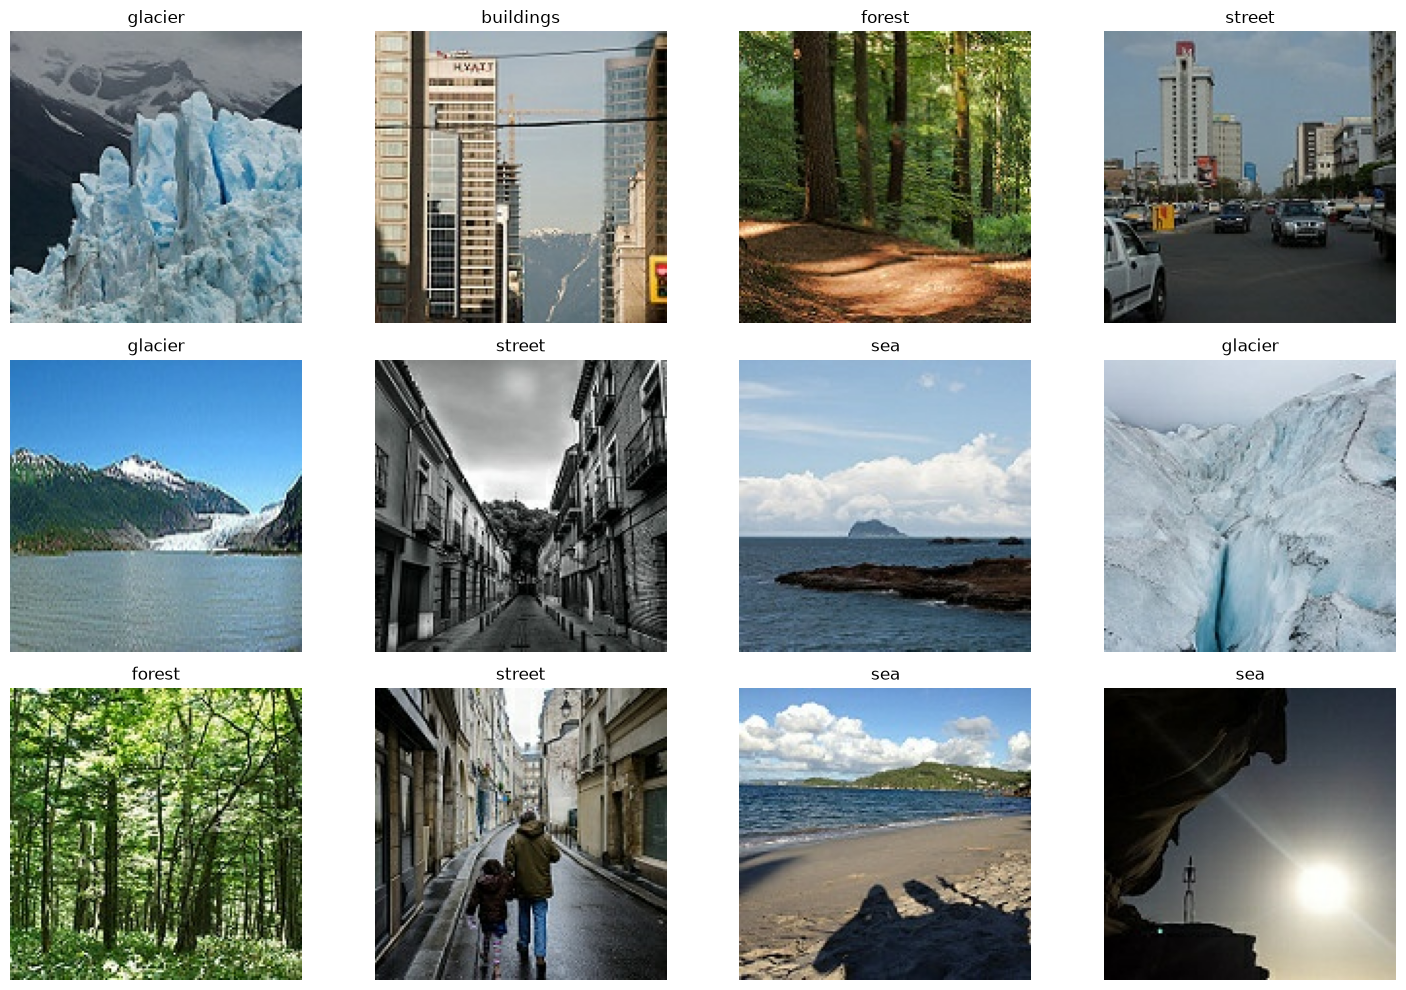

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 10))

for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([

    # Input
    layers.Input(shape=(150, 150, 3)),

    # Bloc convolutionnel 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Bloc convolutionnel 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Bloc convolutionnel 4
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    # Sortie : 6 classes
    layers.Dense(6, activation='softmax')
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 15, 15, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     3,211,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,601,478 (13.74 MB)

 Trainable params: 3,601,478 (13.74 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
print("Nombre de classes :", len(train_ds.class_names))
print("Classes :", train_ds.class_names)

Nombre de classes : 6
Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [27]:
#entrainez le CNN pendant 10 epoques.Afficher les valeurs de loss et accuracy pour les données d'entrainement et de validation (accuracy et val_accuracy). Afficher les courbes de loss et accuracy pour les données d'entrainement et de validation.

In [28]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10
)

Epoch 1/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 235s 532ms/step - accuracy: 0.5767 - loss: 1.8905 - val_accuracy: 0.6397 - val_loss: 0.9264
Epoch 2/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 252s 573ms/step - accuracy: 0.7027 - loss: 0.8015 - val_accuracy: 0.7147 - val_loss: 0.8112
Epoch 3/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 210s 477ms/step - accuracy: 0.7630 - loss: 0.6639 - val_accuracy: 0.7150 - val_loss: 0.7189
Epoch 4/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 185s 420ms/step - accuracy: 0.7891 - loss: 0.5880 - val_accuracy: 0.8097 - val_loss: 0.5678
Epoch 5/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 212s 483ms/step - accuracy: 0.8079 - loss: 0.5401 - val_accuracy: 0.8167 - val_loss: 0.5530
Epoch 6/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 212s 484ms/step - accuracy: 0.8286 - loss: 0.4807 - val_accuracy: 0.8150 - val_loss: 0.5478
Epoch 7/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 229s 523ms/step - accuracy: 0.8473 - loss: 0.4339 - val_accuracy: 0.8177 - val_loss: 0.5444
Epoch 8/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 9324s 21s/step - accuracy: 0.8527 - 

In [29]:
# Évaluation du modèle
test_loss, test_accuracy = model.evaluate(test_ds)

# Afficher résultats en pourcentage
print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 12s 125ms/step - accuracy: 0.8113 - loss: 0.5834
Test Loss : 0.5834
Test Accuracy : 81.13%
